# Amortized policy improvement, round 2: the 0006 value decoder (Phase A)

## Description

<!-- Written 2026-11-11 before the first run (pre-registration). Design: research_log/decisions/0006 §3, §4 Phase A; round 1: notebook 06. Issue #13. -->

**Question.** Round 1 (notebook 06, NO-GO) had clairvoyant headroom over EI: 0.70 % of the gap per state, carried by the top 10% of states. But its value head could not rank candidates (validation Spearman −0.01), and its conservative rule fell back to EI.

Does the 0006 value decoder learn a usable advantage from the same kind of labels, and does one step of policy improvement with it beat EI?

**Setup.**
- *Base policy, candidates, labels*: as round 1.
  - π₀ = EI on the frozen noise-free `pfn_large`; the candidate set C(s) has 133 candidates and x₀ = EI's pick.
  - Labels:
    - the 4000 pinned round-1 states (split 4, instances 0–3999), plus 8000 new states made the same way (instances 4000–11999);
    - 16 labeled candidates per state, 4 ground-truth continuations each, CRN across candidates;
    - d = 2, T = 20.
- *Decoder* (0006 §3):
  - candidate queries are a linear embedding of set-independent features of x (x; the PFN's marginal at x relative to the incumbent; EI, PI; distances; source flag);
  - no candidate–candidate attention;
  - 4 blocks of width 256. Block b cross-attends to the PFN's residual context states at layer 2b (the decoder's own LayerNorm and projection), plus a state token (budget), a statistics token (round 1's global features) and an x₀ token;
  - adaptive LayerNorm on the budget;
  - output: a 63-bin bar distribution (signed-log borders, see the revision below) over the single-seed paired advantage R(x₀, k) − R(x, k), in % of the gap, trained by NLL on every seed (not the seed mean). There is a bin of half-width 0.001 at 0.
- *Null*: the same decoder trained on targets permuted across each state's non-base candidates.
- *Rule* (0006 §3): deviate to the candidate with the largest score if the score exceeds 0.001 (the zero bin's upper edge), else EI's pick.
  - The score is a quantile of the predicted advantage (levels 0.1, 0.3, 0.5) or its mean.
  - rule\* = the best mean normalized regret on split 0 (300 tasks; ties go to the more conservative rule).
- *Test*: split 1, the same 1000 tasks as round 1 (same seeds, offset 0, CRN). Arms: EI, the decoder at every rule, the null decoder at rule\*.

**Deviation from 0006 §2.**
- Candidates are not yet refined by gradient ascent through the query path. That would change π₀, so the round-1 labels would no longer apply.
- x₀ is still exactly the rollouts' EI pick (`Engine.propose("ei")`, tested).

**Revision after the sanity run (2026-11-11 16:43, before the pilot).** Most single-seed advantages lie within ±0.002, and quantile borders collapsed to 25 bins.

The pilot uses signed-log borders instead:
- the zero bin [−0.001, 0.001];
- 31 log-spaced bins per side, up to 1.5 × the largest |a|; 63 bins in all.

On the round-1 labels, 59% of non-base single-seed targets fall in the zero bin, and the other bins hold up to 1.3% each. The rule and the decision criterion are unchanged.

The sanity also showed that the "mean" rule deviates almost always (99% of steps; heavy tails make the mean positive), with a test regret of 9.2 against EI's 1.0. The calibration on split 0 is what guards against this; it stays as pre-registered.

**What to look for.**
- On validation, the within-state Spearman between the predicted mean and the label (round 1: −0.01).
- How often the decoder deviates, from which sources, and in which steps.
- π₁ at rule\* against EI, paired by task.
- The same comparison against round 1's π₁ at c\* = 1, which ran on the same 1000 test tasks. Its EI arm must be identical, which the notebook checks.

**GO / NO-GO** (rule `analysis/api.py::api_verdict`, as round 1, on `paired_delta(test, "dec_<rule*>", "ei")` and the null):
- **INVALID**: the null beats EI with its CI below 0 (a gain without information means a bug or leakage).
- **GO**: the mean normalized regret at rule\* is lower by ≥ 5% relative, with the CI of the difference below 0.
- **NO-GO**: the CI rules out a 5% relative gain.
- **INCONCLUSIVE**: otherwise.

A GO starts Phase B planning (noisy two-head PFN) and gradient-refined candidates. A NO-GO with a clearly better ranking than round 1 points to more labels or the readout. A NO-GO without it points to the label noise (the split-half reliability of notebook 08) or to C(s).

**Limits.**
- One PFN, d = 2, T = 20, noise-free; the expected headroom is small here (0006 §4).
- Labels come from 4 continuations; the single-seed targets are heavy-tailed.
- 12 000 states for a model of about 3M parameters.
- One seed of decoder training.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anytime_acq.analysis import load_snapshot, show_header
from anytime_acq.analysis.api import api_verdict, paired_delta
from anytime_acq.analysis.stats import bootstrap_ci
from anytime_acq.experimental.api import SOURCES

SNAPSHOT = "/home/ruhkopf/PycharmProjects/anytime-acquisition-api/results/api_decoder/pilot_20261111-165340"
ROUND1 = "results/api_round1/pilot_20261111-133311"
snap = load_snapshot(SNAPSHOT)
show_header(snap)  # how it was run + configuration, generated from the snapshot

## How it was run

```bash
just sweep detached pilot experiment=api_decoder task.d=2
```

|  |  |
|---|---|
| stage | pilot |
| sweep | `pilot_20261111-165340` |
| commit | `4274e77f8c51` (tag `sweep/api_decoder/pilot_20261111-165340`) |
| backend / host | detached / ulysses |
| ran | 2026-11-11T16:53:42 → 2026-11-11T21:53:45 |
| members | 1: 1 done |
| compute | 5.0 h wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/api_decoder.yaml`):

```yaml
# @package _global_
# Amortized policy improvement, round 2 (research_log/decisions/0006): the query decoder over EI with a
# calibrated quantile rule, against EI. Pre-registration: notebooks/09_2026-11-11_api_decoder.ipynb.
# Labels on split 4 (round 1's + new), the rule calibrated on split 0, test on split 1 (never selected on).
defaults:
  - override /task: api_decoder

task:
  d: 2
```

**Varying:** nothing

**Replicates:** none

**Constant:**

```yaml
seed: 0
task:
  T_per_d: 10
  api_candidates.local_sigmas: '[0.01, 0.03, 0.1]'
  api_candidates.n_global: 64
  api_candidates.n_local_per_point: 16
  api_candidates.n_top: 4
  calib.n_tasks: 300
  calib.rules: '["q0.1", "q0.3", "q0.5", "mean"]'
  calib.split: 0
  calib.task_offset: 0
  candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  candidates.n_local: 64
  candidates.n_sobol: 1024
  chunk: 256
  d: 2
  decoder.blocks: 4
  decoder.heads: 4
  decoder.n_bins: 64
  decoder.read: '[2, 4, 6, 8]'
  decoder.width: 256
  decoder.zero_eps: 0.001
  device: cuda
  eps: 0.0001
  group: 256
  label.behaviour.ei: 0.8
  label.behaviour.pi: 0.1
  label.behaviour.ucb0.99: 0.1
  label.chunk_tasks: 1000
  label.n_cont: 4
  label.n_labeled: 16
  label.n_tasks: 8000
  label.split: 4
  label.task_draw.n_dense: 4096
  label.task_draw.n_refine: 8
  label.task_draw.refine_steps: 50
  label.task_offset: 4000
  label.val_frac: 0.1
  labels.path: api_round1/pilot_20261111-133311/0/tracking/artifacts/labels.pt
  labels.sha256: c27d893923d0f003ed7b1e1148ad6670c1f5fb061ac7cdf137eb2a8a64c678d9
  n_init_per_d: 2
  name: api_decoder
  pfn: pfn_large
  task_draw.n_dense: 16384
  task_draw.n_refine: 16
  task_draw.refine_steps: 200
  test.n_tasks: 1000
  test.split: 1
  test.task_offset: 0
  tf32: false
  train.batch: 64
  train.epochs: 60
  train.lr: 0.0003
  train.patience: 8
  train.wd: 0.01
```

In [ ]:
runs = snap.runs
print("member status:", runs.status.value_counts().to_dict())
S = runs.iloc[0]
RULES = ["q0.1", "q0.3", "q0.5", "mean"]  # task.calib.rules, conservative first
RULE = RULES[int(S["calib/rule_star_index"])]
ARM, NULL = f"dec_{RULE}", f"null_{RULE}"
print("rule* (calibrated on split 0):", RULE, "| labeled states:", int(S["labels/n_states"]), "| bins:", int(S["bars/n_bins"]))
print("minutes:", {k: round(float(S[k]) / 60, 1) for k in runs.columns if k.startswith("time/")})
val, calib, test = snap.table("val"), snap.table("calib"), snap.table("test")
dec, best = snap.table("decisions"), snap.table("best")
print("val states:", val.state.nunique(), "| test tasks:", test.task.nunique(), "| arms:", sorted(test.arm.unique()))

member status: {'DONE': 1}
rule* (calibrated on split 0): q0.5 | labeled states: 12000 | bins: 63
minutes: {'time/calib_s': 2.7, 'time/inputs_s': 0.1, 'time/labels_s': 286.2, 'time/test_s': 10.3, 'time/train_s': 0.8}
val states: 1204 | test tasks: 1000 | arms: ['dec_mean', 'dec_q0.1', 'dec_q0.3', 'dec_q0.5', 'ei', 'null_q0.5']


## 1. Training

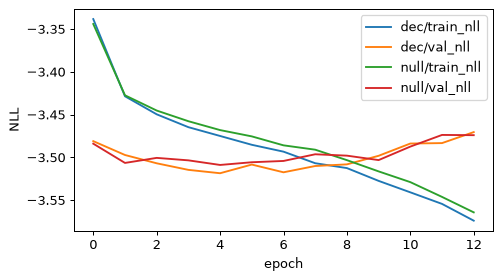

{'dec/best_val_nll': -3.5185, 'null/best_val_nll': -3.5088, 'dec/epochs': 13.0, 'null/epochs': 13.0}


In [ ]:
cur = snap.curves()
fig, ax = plt.subplots(1, 1, figsize=(6, 3.2), dpi=90)
for k in ("dec/train_nll", "dec/val_nll", "null/train_nll", "null/val_nll"):
    c = cur.loc[cur.key == k]
    ax.plot(c.step, c.value, label=k)
ax.set_xlabel("epoch"); ax.set_ylabel("NLL"); ax.legend(); plt.show()
print({k: round(float(S[k]), 4) for k in ("dec/best_val_nll", "null/best_val_nll", "dec/epochs", "null/epochs")})

## 2. Validation: does the decoder rank the candidates of a state?

The within-state Spearman between a score and the seed-averaged label, over the valid non-base labeled candidates of each held-out state (round 1's head: −0.01).

In [ ]:
v = val.loc[val.valid & (val.j > 0)]
rows = []
for col in ("mean", "q0.1", "q0.3", "q0.5"):
    rho = v.groupby("state").apply(lambda d: d[col].corr(d["adv"], method="spearman"), include_groups=False).dropna()
    lo, hi = bootstrap_ci(rho.to_numpy())
    rows.append({"score": col, "within_spearman": rho.mean(), "lo": lo, "hi": hi, "n_states": len(rho)})
display(pd.DataFrame(rows).round(3))
# calibration of the predicted mean: binned prediction vs realized label
v = v.assign(bin=pd.qcut(v["mean"], 10, duplicates="drop"))
display(v.groupby("bin", observed=True).agg(pred=("mean", "mean"), label=("adv", "mean"), n=("adv", "size")).round(3))
# the decoder's own choice per validation state (score > zero_eps at rule*) and its label
sc = RULE if RULE != "mean" else "mean"
ch = val.loc[val.valid & (val.j > 0)].sort_values(sc).groupby("state").tail(1)
ch = ch.assign(adv_choice=np.where(ch[sc] > 1e-3, ch.adv, 0.0))
lo, hi = bootstrap_ci(ch.adv_choice.to_numpy())
print(f"label of the decoder's choice at rule* on validation states: {ch.adv_choice.mean():.3f} [{lo:.3f}, {hi:.3f}] | deviation share {(ch[sc] > 1e-3).mean():.3f}")

/home/ruhkopf/PycharmProjects/anytime-acquisition-api/.venv/lib/python3.12/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


/home/ruhkopf/PycharmProjects/anytime-acquisition-api/.venv/lib/python3.12/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


/home/ruhkopf/PycharmProjects/anytime-acquisition-api/.venv/lib/python3.12/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


/home/ruhkopf/PycharmProjects/anytime-acquisition-api/.venv/lib/python3.12/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


,score,within_spearman,lo,hi,n_states
0,mean,-0.020,-0.042,0.001,932
1,q0.1,0.029,0.008,0.050,932
2,q0.3,0.049,0.028,0.070,932
3,q0.5,0.060,0.039,0.081,932


,pred,label,n
bin,,,
"(-0.605, -0.0913]",-0.177,0.185,1806
"(-0.0913, -0.0196]",-0.052,-0.019,1806
"(-0.0196, 0.015]",0.001,-0.023,1806
"(0.015, 0.0234]",0.020,-0.002,1806
"(0.0234, 0.031]",0.027,0.035,1806
"(0.031, 0.0413]",0.036,0.070,1806
"(0.0413, 0.0558]",0.048,-0.009,1806
"(0.0558, 0.0749]",0.065,0.121,1806
"(0.0749, 0.108]",0.089,0.074,1806


label of the decoder's choice at rule* on validation states: -0.002 [-0.005, 0.000] | deviation share 0.002


## 3. Calibration of the rule (split 0) and test (split 1)

In [ ]:
display(calib.groupby("arm").norm_regret.mean().to_frame("calib mean norm_regret").round(4))
res = {a: paired_delta(test, a, "ei") for a in sorted(test.arm.unique()) if a != "ei"}
display(pd.DataFrame(res).T[["delta", "lo", "hi", "rel", "rel_lo", "rel_hi", "frac_a_better", "frac_tied"]].astype(float).round(4))
main, null = res[ARM], res[NULL]
print("rule*:", RULE, "| main:", {k: round(float(main[k]), 4) for k in ("delta", "lo", "hi", "rel")})
dl = paired_delta(test, ARM, "ei", col="log_regret")
print("log_regret:", {k: round(float(dl[k]), 4) for k in ("delta", "lo", "hi")})

,calib mean norm_regret
arm,
dec_mean,3.7712
dec_q0.1,1.0600
dec_q0.3,1.0600
dec_q0.5,1.0502
ei,1.0600


,delta,lo,hi,rel,rel_lo,rel_hi,frac_a_better,frac_tied
dec_mean,2.0905,1.6315,2.5827,1.5661,1.2223,1.9349,0.155,0.052
dec_q0.1,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.000,1.000
dec_q0.3,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.000,1.000
dec_q0.5,-0.0013,-0.0142,0.0116,-0.0010,-0.0107,0.0087,0.011,0.986
null_q0.5,0.0003,-0.0019,0.0030,0.0002,-0.0015,0.0023,0.430,0.156


rule*: q0.5 | main: {'delta': -0.0013, 'lo': -0.0142, 'hi': 0.0116, 'rel': -0.001}
log_regret: {'delta': -0.0048, 'lo': -0.0113, 'hi': -0.0002}


## 4. Against round 1 (same 1000 test tasks, CRN): the decoder vs round 1's π₁ at c\* = 1

In [ ]:
r1s = load_snapshot(ROUND1)
fin = lambda b: b.loc[b.t == b.t.max()].pivot_table(index="seed", columns="arm", values="best_f")  # noqa: E731
f1, f2 = fin(r1s.table("best")), fin(best)
f2 = f2.loc[f2.index.isin(f1.index)]
f1 = f1.loc[f2.index]
print("EI trajectories identical across rounds (final best f):", bool(np.allclose(f1.ei, f2.ei, atol=1e-6)),
      "| max |diff|:", float((f1.ei - f2.ei).abs().max()), "| tasks:", len(f2))
# common normalization: f* lowered by every arm of both rounds, f_med of round 1 (the same tasks)
fs1 = r1s.table("fstar").set_index("seed").loc[f2.index]
fs2 = snap.table("fstar").set_index("seed").loc[f2.index]
fstar = np.minimum(np.minimum(fs1.fstar, fs2.fstar), np.minimum(f1.min(axis=1), f2.min(axis=1)))
nr = lambda f: 100 * (f - fstar).clip(lower=0) / (fs1.fmed - fstar).clip(lower=1e-9)  # noqa: E731
m = pd.DataFrame({"r2": nr(f2[ARM]), "r1": nr(f1["api_c1"]), "ei": nr(f2.ei)}).reset_index()
m = m.melt(id_vars="seed", var_name="arm", value_name="norm_regret").rename(columns={"seed": "task"})
for a, b in (("r2", "r1"), ("r2", "ei"), ("r1", "ei")):
    d = paired_delta(m, a, b)
    print(f"{a} − {b}:", {k: round(float(d[k]), 4) for k in ("delta", "lo", "hi", "rel", "rel_lo", "rel_hi")})

EI trajectories identical across rounds (final best f): True | max |diff|: 3.2782554626464844e-07 | tasks: 1000


r2 − r1: {'delta': 0.0088, 'lo': -0.0119, 'hi': 0.0381, 'rel': 0.0067, 'rel_lo': -0.009, 'rel_hi': 0.0287}
r2 − ei: {'delta': -0.0013, 'lo': -0.0142, 'hi': 0.0116, 'rel': -0.001, 'rel_lo': -0.0107, 'rel_hi': 0.0087}


r1 − ei: {'delta': -0.0101, 'lo': -0.0329, 'hi': 0.0021, 'rel': -0.0076, 'rel_lo': -0.0246, 'rel_hi': 0.0016}


## 5. Decisions on the test split

deviation rate: 0.002


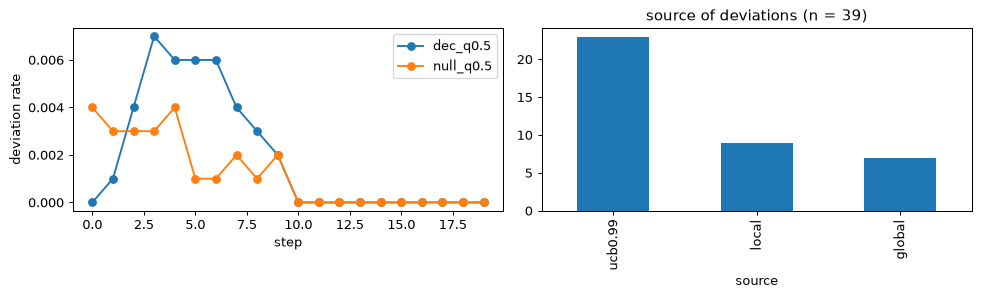

In [ ]:
dd = dec.loc[dec.arm == ARM]
print("deviation rate:", round(float(dd.deviated.mean()), 3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), dpi=90)
for a in (ARM, NULL):
    dec.loc[dec.arm == a].groupby("step").deviated.mean().plot(ax=ax[0], marker="o", label=a)
ax[0].set_ylabel("deviation rate"); ax[0].set_xlabel("step"); ax[0].legend()
src = dd.loc[dd.deviated].source.map(dict(enumerate(SOURCES))).value_counts()
if len(src): src.plot.bar(ax=ax[1])
ax[1].set_title(f"source of deviations (n = {int(src.sum())})")
plt.tight_layout(); plt.show()

## Observations (pilot, snapshot `results/api_decoder/pilot_20261111-165340`)

Written after the run.
- **The decision.**
  - The calibrated rule\* is q0.5. On 1000 split-1 tasks it deviates at 0.2% of the steps.
  - Δ norm_regret vs EI = −0.0013 [−0.014, 0.012], relative −0.1% [−1.1%, +0.9%]. The CI rules out a 5% gain, so the verdict is **NO-GO**.
  - log_regret: −0.0048 [−0.011, −0.0002]. This is secondary, tiny, and comes from about 1% of the tasks that differ.
- **The decoder learns about as much ranking as EI already has.**
  - Within-state Spearman on validation states: q0.5 0.060 [0.039, 0.081], q0.3 0.049, q0.1 0.029, mean −0.020.
  - Untrained log EI scores 0.063 against the same kind of labels (notebook 08 addendum).
  - The label reliability is 0.57, so the ceiling is far away. 12000 labeled states and 13 epochs did not get close to it.
- **The decoder vs the null.**
  - Validation NLL is −3.519 vs −3.509: almost no difference, so permuting the advantages within a state costs the decoder almost nothing.
  - The predicted-vs-label table: only the extreme bins carry signal, and the lowest bin is *inverted* (pred −0.18, label +0.19).
- **The mean rule** is catastrophic again (calib 3.77 vs EI 1.06). The bar distribution's mean is pulled by the heavy tails and deviates far too often. The conservative quantile rules almost never deviate.
- **Against round 1.**
  - The EI trajectories are identical (max |Δ| 3e-7).
  - r2 − r1 = +0.009 [−0.012, 0.038]; round 1's π₁ − EI = −0.010 [−0.033, 0.002]. Neither round improves on EI.
- **Reading.** This agrees with notebooks 07 and 08: at these states the candidates' ground-truth advantage over EI's pick is not predictable from the PFN's belief. A supervised decoder trained on 12000 labeled states learns nothing beyond EI's own ranking, so it (correctly) stays with EI.


## Verdict

In [ ]:
print("verdict (analysis/api.py::api_verdict):", api_verdict(main, null))

verdict (analysis/api.py::api_verdict): NO-GO
